<a href="https://colab.research.google.com/github/hodamalak/data-science-python-projects/blob/main/Deep%20Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Name: Hoda Malak

ID: 11734843

In [ ]:
pip install tensorflow scikeras

In [ ]:
!pip install scikit-learn==1.2.2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 22.5 MB/s eta 0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
scikeras 0.13.0 requires scikit-learn>=1.4.2, but you have scikit-learn 1.2.2 which is incompatible.
mlxtend 0.23.4 requires scikit-learn>=1.3.1, but you have scikit-learn 1.2.2 which is incompatible.
imbalanced-learn 0.13.0 requires scikit-learn<2,>=1.3.2, but you have scikit-learn 1.2.2 which is incompatible.


In [ ]:
# Import necessary libraries
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import tensorflow as tf
import keras as k
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from scikeras.wrappers import KerasClassifier
from keras.models import Sequential
from keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau








In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Load dataset
filename = "/content/drive/MyDrive/Colab Notebooks/pima_diabetes (1).csv"
col_names = ['preg', 'plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age', 'class']
df = pd.read_csv(filename, names=col_names)

Mounted at /content/drive


In [ ]:
# Exploratory Data Analysis (EDA)
print("Dataset Overview:")
print(df.head())

Dataset Overview:
   preg  plas  pres  skin  test  mass   pedi  age  class
0     6   148    72    35     0  33.6  0.627   50      1
1     1    85    66    29     0  26.6  0.351   31      0
2     8   183    64     0     0  23.3  0.672   32      1
3     1    89    66    23    94  28.1  0.167   21      0
4     0   137    40    35   168  43.1  2.288   33      1


In [ ]:
# Check for missing values
print("\nMissing Values in Dataset:")
print(df.isnull().sum())


Missing Values in Dataset:
preg     0
plas     0
pres     0
skin     0
test     0
mass     0
pedi     0
age      0
class    0
dtype: int64


In [ ]:
# Split dataset into features (X) and target variable (y)
X = df.iloc[:, :-1].values  # Features
y = df.iloc[:, -1].values   # Target (1 = Diabetes, 0 = No Diabetes)

In [ ]:
# Encode labels (if necessary)
encoder = LabelEncoder()
y = encoder.fit_transform(y)

In [ ]:
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# Standardizing data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
# Define MLP Model (Two-Layer Network)
def build_mlp2():
    model = Sequential()

    # Input Layer + First Hidden Layer (8 neurons)
    model.add(Dense(8, input_dim=8, activation='relu'))

    # Second Hidden Layer (2 neurons)
    model.add(Dense(2, activation='relu'))

    # Output Layer (2 neurons, using softmax for classification)
    model.add(Dense(2, activation='softmax'))

    # Compile the Model
    optimizer = Adam(learning_rate=0.001)
    model.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics=['accuracy'])#sparse_categorical_crossentropy

    return model

In [ ]:
# Create Model
model = build_mlp2()

In [ ]:
# Implement Learning Rate Reduction on Plateau
lr_reduction = ReduceLROnPlateau(monitor='val_loss', patience=5, verbose=1, factor=0.5, min_lr=0.0001)


In [ ]:
# Train the Model
history = model.fit(X_train, y_train, validation_split=0.2, epochs=100, batch_size=10, callbacks=[lr_reduction], verbose=1)


Epoch 1/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.6632 - loss: 0.6751 - val_accuracy: 0.5772 - val_loss: 0.7578 - learning_rate: 0.0010
Epoch 2/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5853 - loss: 0.6933 - val_accuracy: 0.6098 - val_loss: 0.7039 - learning_rate: 0.0010
Epoch 3/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6189 - loss: 0.6354 - val_accuracy: 0.6341 - val_loss: 0.6651 - learning_rate: 0.0010
Epoch 4/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6416 - loss: 0.5965 - val_accuracy: 0.6504 - val_loss: 0.6386 - learning_rate: 0.0010
Epoch 5/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6575 - loss: 0.5488 - val_accuracy: 0.6667 - val_loss: 0.6173 - learning_rate: 0.0010
Epoch 6/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6566 - loss: 0.5614 - val_accuracy: 0.6748 - val_loss: 0.6033 - learning_rate: 0.0010
Epoch 7/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6907 - loss: 0.5349 - val_acc

In [ ]:
# Evaluate Model on Test Set
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy (accuracy_evaluation): {test_accuracy * 100:.2f}%")

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6526 - loss: 0.5902 
Test Accuracy (accuracy_evaluation): 68.83%


In [ ]:
# Plot Training & Validation Loss and Accuracy
def plot_training_history(history):
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    # Loss Plot
    ax[0].plot(history.history['loss'], label='Train Loss')
    ax[0].plot(history.history['val_loss'], label='Validation Loss')
    ax[0].set_title('Model Loss')
    ax[0].set_xlabel('Epochs')
    ax[0].set_ylabel('Loss')
    ax[0].legend()

    # Accuracy Plot
    ax[1].plot(history.history['accuracy'], label='Train Accuracy')
    ax[1].plot(history.history['val_accuracy'], label='Validation Accuracy')
    ax[1].set_title('Model Accuracy')
    ax[1].set_xlabel('Epochs')
    ax[1].set_ylabel('Accuracy')
    ax[1].legend()

    plt.show()

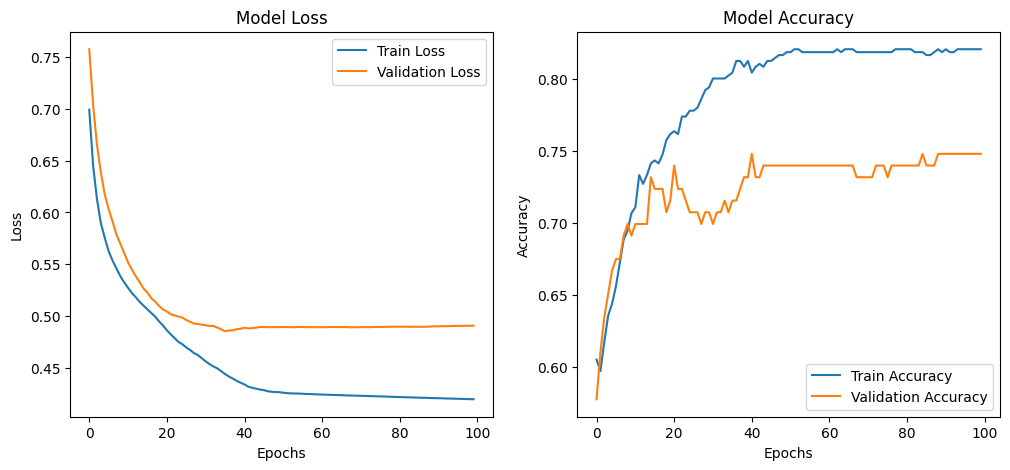

In [ ]:
# Display Training Progress
plot_training_history(history)

In [ ]:
# Define 10-Fold Cross-Validation Model
def build_cv_model():
    return build_mlp2()

cv_model = KerasClassifier(model=build_cv_model, epochs=200, batch_size=5, verbose=0)

In [ ]:
# Define 10-Fold Cross-Validation
kfold = KFold(n_splits=10, shuffle=True, random_state=7)

In [ ]:
# Perform Cross-Validation
results = cross_val_score(cv_model, X_train, y_train, cv=kfold)

In [ ]:
# Print Cross-Validation Results
print(f"10-Fold Cross-Validation Accuracy (accuracy_training): {results.mean() * 100:.2f}% (±{results.std() * 100:.2f}%)")

10-Fold Cross-Validation Accuracy (accuracy_training): 76.56% (±2.74%)
